# Credit Risk Modeling - Phase 2: WoE Scorecard and Calibration

Phase 1 established an evaluation benchmark (5-fold CV ROC-AUC: XGBoost 0.769 +/- 0.052,
Logistic Regression 0.750 +/- 0.055). Phase 2 builds a traditional credit scorecard and asks:

1. Can the model be explained bin by bin? (optimal binning, WoE, IV, logistic regression on WoE)
2. How much discrimination do we give up for that transparency? (CV AUC vs Phase 1 benchmark)
3. Are the predicted PDs trustworthy as probabilities? (reliability diagram, Brier score)
4. Where should the cut-off be from a business point of view? (strategy curve: approval rate vs bad rate)

Conventions (same as Phase 1): `1 = bad` (event). optbinning defines WoE = ln(%good / %bad),
so a higher WoE means lower risk. Scorecard scaling: 600 points at good:bad odds of 50:1, PDO = 20;
a higher score means lower risk.

## 1. Setup

In [1]:
# On Colab: install optbinning (pulls ortools); restart the session if prompted
!pip install -q optbinning

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from optbinning import BinningProcess, Scorecard
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

import optbinning, sklearn, xgboost
print("optbinning", optbinning.__version__, "| scikit-learn", sklearn.__version__,
      "| xgboost", xgboost.__version__)

RANDOM_STATE = 42  # same as Phase 1 so the train/test split is identical

(CVXPY) Nov 09 08:30:35 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')
(CVXPY) Nov 09 08:30:35 PM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Nov 09 08:30:35 PM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Nov 09 08:30:35 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


optbinning 1.0.0 | scikit-learn 1.6.1 | xgboost 3.4.1


## 2. Load data and reproduce the Phase 1 split

In [2]:
LOCAL_CSV = os.environ.get("CREDIT_CSV")
if LOCAL_CSV:
    csv_path = LOCAL_CSV
else:
    import kagglehub
    path = kagglehub.dataset_download("kabure/german-credit-data-with-risk")
    csv_path = os.path.join(path, "german_credit_data.csv")

df = pd.read_csv(csv_path).drop(columns=["Unnamed: 0"], errors="ignore")
df[["Saving accounts", "Checking account"]] = df[["Saving accounts", "Checking account"]].fillna("none")
df["target"] = (df["Risk"] == "bad").astype(int)

num_features = ["Age", "Credit amount", "Duration"]
cat_features = ["Job", "Housing", "Saving accounts", "Checking account", "Purpose"]
features = num_features + cat_features

X = df[features].copy()
X["Job"] = X["Job"].astype(str)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape, "| train bad rate:", round(y_train.mean(), 3))

Using Colab cache for faster access to the 'german-credit-data-with-risk' dataset.
(800, 8) (200, 8) | train bad rate: 0.3


## 3. Optimal binning, WoE and IV (fitted on the training set only)

Binning constraints:
- Each bin holds at least 5% of the training rows (`min_bin_size=0.05`) so WoE estimates are stable.
- `Duration`: bad rate must increase with duration (business logic: longer exposure, more risk).
- `Age`, `Credit amount`: let the solver choose an increasing or decreasing monotonic trend
  (`auto_asc_desc`); a non-monotonic pattern on 800 rows is more likely noise than signal.
- Categorical variables: categories with similar bad rates are merged.

In [3]:
binning_fit_params = {
    "Duration": {"monotonic_trend": "ascending"},
    "Age": {"monotonic_trend": "auto_asc_desc"},
    "Credit amount": {"monotonic_trend": "auto_asc_desc"},
}

def make_binning(selection_criteria=None):
    return BinningProcess(
        variable_names=features,
        categorical_variables=cat_features,
        min_bin_size=0.05,
        binning_fit_params=binning_fit_params,
        selection_criteria=selection_criteria,
    )

bp_all = make_binning()
bp_all.fit(X_train, y_train)

iv_table = (bp_all.summary()[["name", "dtype", "status", "n_bins", "iv", "gini"]]
            .sort_values("iv", ascending=False).reset_index(drop=True))

def iv_label(iv):
    if iv < 0.02: return "unpredictive"
    if iv < 0.1: return "weak"
    if iv < 0.3: return "medium"
    if iv <= 0.5: return "strong"
    return "suspicious (check leakage)"

iv_table["strength"] = iv_table["iv"].apply(iv_label)
iv_table

,name,dtype,status,n_bins,iv,gini,strength
0,Checking account,categorical,OPTIMAL,4,0.616798,0.398244,suspicious (check leakage)
1,Duration,numerical,OPTIMAL,6,0.308445,0.276756,strong
2,Saving accounts,categorical,OPTIMAL,5,0.225283,0.212128,medium
3,Credit amount,numerical,OPTIMAL,4,0.1325,0.152039,medium
4,Purpose,categorical,OPTIMAL,5,0.089917,0.151153,weak
5,Housing,categorical,OPTIMAL,3,0.088097,0.137932,weak
6,Age,numerical,OPTIMAL,3,0.074811,0.141473,weak
7,Job,categorical,OPTIMAL,3,0.011232,0.040789,unpredictive


### Binning tables

For each variable: count per bin, bad rate (`Event rate`), WoE and IV contribution.
Check that each table makes business sense before trusting the model.

In [4]:
for var in iv_table["name"]:
    ob = bp_all.get_binned_variable(var)
    bt = ob.binning_table.build()
    print(f"\n===== {var} (IV = {ob.binning_table.iv:.3f}) =====")
    print(bt[["Bin", "Count", "Count (%)", "Event", "Event rate", "WoE", "IV"]].to_string())


===== Checking account (IV = 0.617) =====
               Bin  Count  Count (%)  Event  Event rate       WoE        IV
0           [none]    316    0.39500     38    0.120253  1.142737  0.386354
1           [rich]     51    0.06375     13    0.254902  0.225339  0.003085
2       [moderate]    214    0.26750     84    0.392523  -0.41058  0.048390
3         [little]    219    0.27375    105    0.479452  -0.76506  0.178969
4          Special      0    0.00000      0    0.000000       0.0  0.000000
5          Missing      0    0.00000      0    0.000000       0.0  0.000000
Totals                800    1.00000    240    0.300000            0.616798

===== Duration (IV = 0.308) =====
                   Bin  Count  Count (%)  Event  Event rate       WoE        IV
0         (-inf, 8.50)     74    0.09250      6    0.081081   1.58045  0.152401
1        [8.50, 11.50)     70    0.08750     14    0.200000  0.538997  0.022458
2       [11.50, 15.50)    204    0.25500     50    0.245098  0.277632  0.0

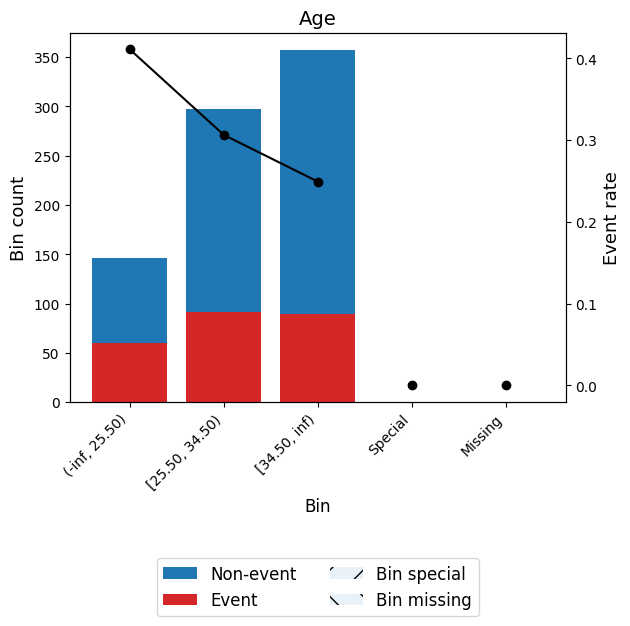

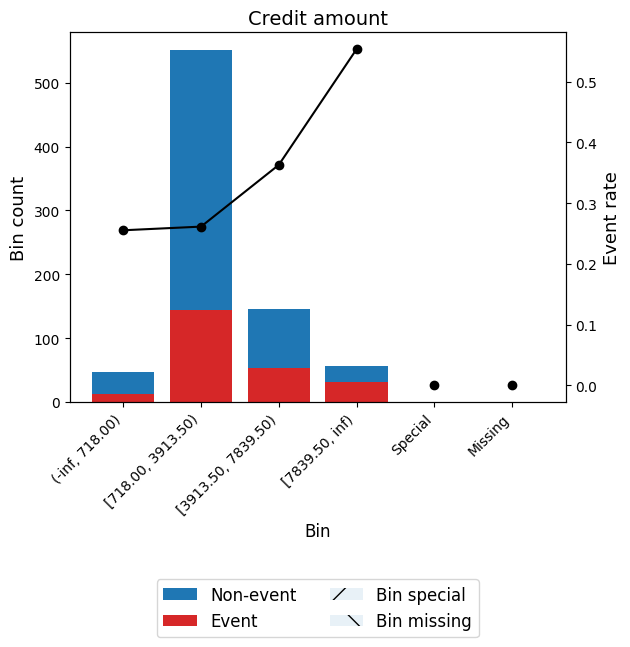

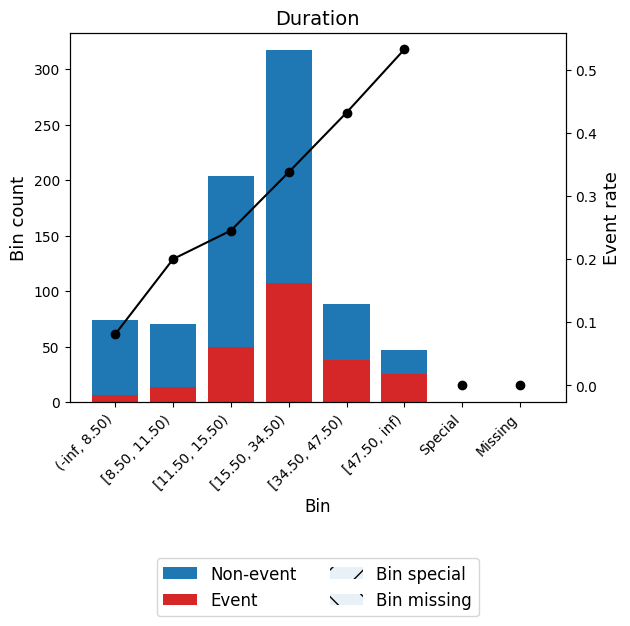

In [5]:
# Bad rate and WoE per bin for the numerical variables
for var in num_features:
    bp_all.get_binned_variable(var).binning_table.plot(metric="event_rate", show_bin_labels=True)

## 4. Variable selection

Rule: keep variables with IV >= 0.02. IV judges one variable at a time, so we also check the
correlation between WoE-transformed variables. A pair with |corr| > 0.6 carries overlapping
information and can produce coefficients with the wrong sign.

Selected: ['Checking account', 'Duration', 'Saving accounts', 'Credit amount', 'Purpose', 'Housing', 'Age']
Dropped: ['Job']


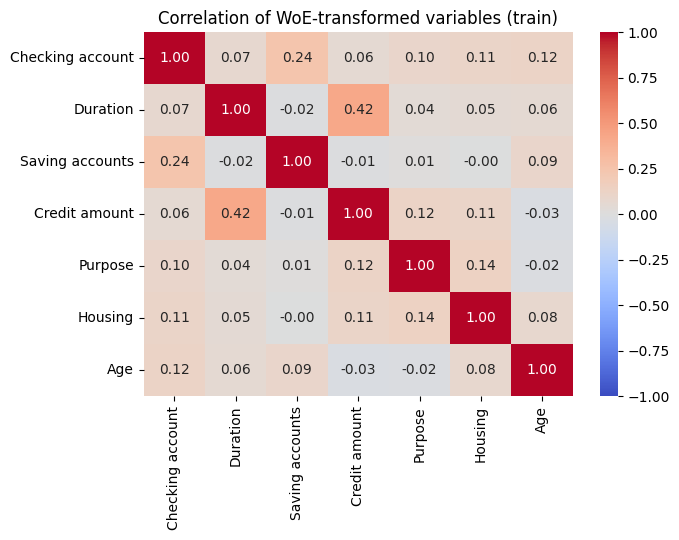

In [6]:
selection_criteria = {"iv": {"min": 0.02}}
selected = iv_table.loc[iv_table["iv"] >= 0.02, "name"].tolist()
print("Selected:", selected)
print("Dropped:", [v for v in features if v not in selected])

woe_train = pd.DataFrame(bp_all.transform(X_train, metric="woe"), columns=features)[selected]
plt.figure(figsize=(7, 5.5))
sns.heatmap(woe_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of WoE-transformed variables (train)")
plt.tight_layout(); plt.show()

## 5. Logistic regression on WoE: cross-validated AUC vs the Phase 1 benchmark

Binning is part of the pipeline, so it is re-fitted inside every CV fold (no leakage from the
validation fold into the bins). `C` is large because binning already regularises the model.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

woe_lr = Pipeline([
    ("binning", make_binning(selection_criteria)),
    ("lr", LogisticRegression(C=1e3, max_iter=1000)),
])

# Phase 1 XGBoost with its tuned parameters, re-fitted here for a like-for-like comparison
xgb_pipe = Pipeline([
    ("prep", ColumnTransformer([
        ("num", "passthrough", num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ])),
    ("model", XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.03, subsample=0.8,
                            colsample_bytree=0.8, scale_pos_weight=1,
                            random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1)),
])

oof = {}
rows = []
for name, model in [("WoE scorecard (LR)", woe_lr), ("XGBoost (Phase 1)", xgb_pipe)]:
    oof[name] = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    fold_auc = [roc_auc_score(y_train.iloc[va], oof[name][va]) for _, va in cv.split(X_train, y_train)]
    rows.append({"model": name, "cv_auc_mean": np.mean(fold_auc), "cv_auc_std": np.std(fold_auc),
                 "oof_auc": roc_auc_score(y_train, oof[name])})

cv_compare = pd.DataFrame(rows)
cv_compare["cv_gini_mean"] = 2 * cv_compare["cv_auc_mean"] - 1
cv_compare

,model,cv_auc_mean,cv_auc_std,oof_auc,cv_gini_mean
0,WoE scorecard (LR),0.750763,0.044713,0.749624,0.501525
1,XGBoost (Phase 1),0.768973,0.052363,0.769144,0.537946


In [8]:
# Paired comparison: the same folds are used for both models, so look at the per-fold difference
diffs = []
for _, va in cv.split(X_train, y_train):
    a = roc_auc_score(y_train.iloc[va], oof["WoE scorecard (LR)"][va])
    b = roc_auc_score(y_train.iloc[va], oof["XGBoost (Phase 1)"][va])
    diffs.append(a - b)
print("Per-fold AUC difference (scorecard - XGBoost):", np.round(diffs, 3))
print(f"Mean difference: {np.mean(diffs):+.3f}  (std {np.std(diffs):.3f})")

Per-fold AUC difference (scorecard - XGBoost): [-0.05  -0.016  0.006 -0.004 -0.027]
Mean difference: -0.018  (std 0.019)


## 6. Fit the final scorecard

Scaling: Score = Offset + Factor * ln(odds_good), Factor = PDO / ln 2, Offset = 600 - Factor * ln 50.

Coefficient sanity check: with `y = 1` for bad and WoE = ln(%good / %bad), a higher WoE must lower
the probability of bad, so every coefficient should be **negative**. A positive coefficient means
the variable is redundant with another one and should be removed.

In [9]:
PDO, BASE_SCORE, BASE_ODDS = 20, 600, 50

scorecard = Scorecard(
    binning_process=make_binning(selection_criteria),
    estimator=LogisticRegression(C=1e3, max_iter=1000),
    scaling_method="pdo_odds",
    scaling_method_params={"pdo": PDO, "odds": BASE_ODDS, "scorecard_points": BASE_SCORE},
)
scorecard.fit(X_train, y_train)

final_vars = list(scorecard.binning_process_.get_support(names=True))
coefs = pd.Series(scorecard.estimator_.coef_[0], index=final_vars).round(3)
print("Intercept:", round(scorecard.estimator_.intercept_[0], 3))
print(coefs.to_string())
print("\nAll coefficients negative:", bool((coefs < 0).all()))

Intercept: -0.847
Age                -0.728
Credit amount      -0.394
Duration           -0.859
Housing            -0.558
Saving accounts    -0.789
Checking account   -0.843
Purpose            -0.823

All coefficients negative: True


In [10]:
sc_table = scorecard.table(style="detailed")
pd.set_option("display.max_rows", 100)
sc_table[["Variable", "Bin", "Count (%)", "Event rate", "WoE", "Points"]].round(3)

,Variable,Bin,Count (%),Event rate,WoE,Points
0,Age,"(-inf, 25.50)",0.182,0.411,-0.487,62.846
1,Age,"[25.50, 34.50)",0.371,0.306,-0.030,72.444
2,Age,"[34.50, inf)",0.446,0.249,0.255,78.436
3,Age,Special,0.000,0.000,0.000,73.079
4,Age,Missing,0.000,0.000,0.000,73.079
0,Credit amount,"(-inf, 718.00)",0.059,0.255,0.223,75.614
1,Credit amount,"[718.00, 3913.50)",0.689,0.261,0.192,75.257
2,Credit amount,"[3913.50, 7839.50)",0.182,0.363,-0.285,69.842
3,Credit amount,"[7839.50, inf)",0.070,0.554,-1.062,61.010
4,Credit amount,Special,0.000,0.000,0.000,73.079


Factor: 28.854 | Offset: 487.123
Score matches scaled log-odds: True


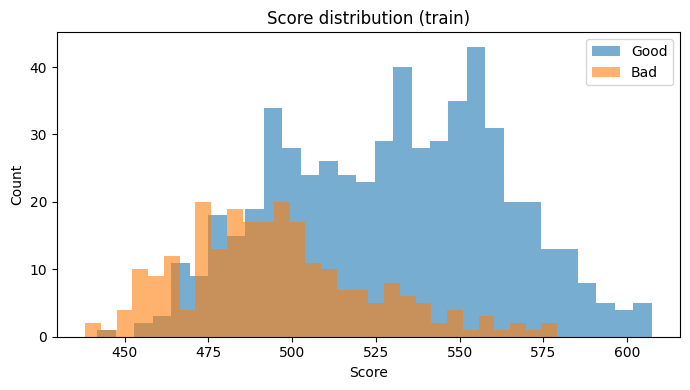

In [11]:
# Check that the score is exactly the scaled log-odds of being good
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)

def pd_to_score(p):
    return offset + factor * np.log((1 - p) / p)

def score_to_pd(s):
    return 1 / (1 + np.exp((s - offset) / factor))

train_score = scorecard.score(X_train)
train_pd = scorecard.predict_proba(X_train)[:, 1]
print("Factor:", round(factor, 3), "| Offset:", round(offset, 3))
print("Score matches scaled log-odds:", np.allclose(train_score, pd_to_score(train_pd)))

plt.figure(figsize=(7, 4))
plt.hist(train_score[y_train.to_numpy() == 0], bins=30, alpha=0.6, label="Good")
plt.hist(train_score[y_train.to_numpy() == 1], bins=30, alpha=0.6, label="Bad")
plt.xlabel("Score"); plt.ylabel("Count"); plt.title("Score distribution (train)")
plt.legend(); plt.tight_layout(); plt.show()

## 7. Held-out test evaluation (scorecard vs XGBoost)

In [12]:
xgb_pipe.fit(X_train, y_train)
test_pd = {
    "WoE scorecard (LR)": scorecard.predict_proba(X_test)[:, 1],
    "XGBoost (Phase 1)": xgb_pipe.predict_proba(X_test)[:, 1],
}
y_arr = y_test.to_numpy()
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(y_arr), len(y_arr)) for _ in range(1000)]
boot_idx = [i for i in boot_idx if 0 < y_arr[i].sum() < len(i)]

rows = []
for name, p in test_pd.items():
    fpr, tpr, _ = roc_curve(y_arr, p)
    auc = roc_auc_score(y_arr, p)
    boot = [roc_auc_score(y_arr[i], p[i]) for i in boot_idx]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows.append({"model": name, "test_auc": round(auc, 3), "auc_95ci": f"{lo:.3f} - {hi:.3f}",
                 "gini": round(2 * auc - 1, 3), "ks": round(np.max(tpr - fpr), 3)})
test_table = pd.DataFrame(rows)
test_table

,model,test_auc,auc_95ci,gini,ks
0,WoE scorecard (LR),0.780,0.705 - 0.849,0.559,0.455
1,XGBoost (Phase 1),0.785,0.713 - 0.855,0.570,0.450


## 8. Calibration

Discrimination (AUC) only checks the ranking. Calibration checks whether a predicted PD of 20%
really corresponds to about 20% bad customers. We use out-of-fold predictions on the training set
(800 rows) because the test set has only about 60 bad customers.

- Reliability diagram: quantile bins of predicted PD vs observed bad rate. Points on the diagonal = well calibrated.
- Brier score: mean squared error of the PD; compared against a no-skill model that predicts the training bad rate for everyone.

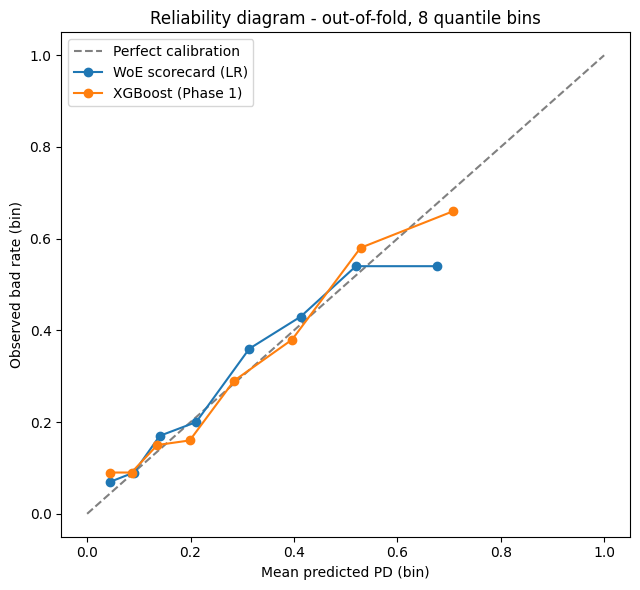

,model,brier_oof
0,No-skill (train bad rate),0.2100
1,WoE scorecard (LR),0.1778
2,XGBoost (Phase 1),0.1693


In [13]:
N_BINS = 8
base_rate = y_train.mean()
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], ls="--", c="gray", label="Perfect calibration")

brier_rows = [{"model": "No-skill (train bad rate)",
               "brier_oof": brier_score_loss(y_train, np.full(len(y_train), base_rate))}]
for name, p in oof.items():
    frac_bad, mean_pred = calibration_curve(y_train, p, n_bins=N_BINS, strategy="quantile")
    ax.plot(mean_pred, frac_bad, marker="o", label=name)
    brier_rows.append({"model": name, "brier_oof": brier_score_loss(y_train, p)})

ax.set_xlabel("Mean predicted PD (bin)"); ax.set_ylabel("Observed bad rate (bin)")
ax.set_title(f"Reliability diagram - out-of-fold, {N_BINS} quantile bins")
ax.legend(); plt.tight_layout(); plt.show()

brier_table = pd.DataFrame(brier_rows)
brier_table["brier_oof"] = brier_table["brier_oof"].round(4)
brier_table

## 8b. Platt scaling check

The scorecard over-predicts PD in the highest-risk bin. Platt scaling fits a 2-parameter logistic
map on the logit of the PD: PD_cal = sigmoid(a + b * logit(PD)).

- `b` is the **calibration slope**: b < 1 means predictions are too extreme (over-confident), b > 1 too timid.
- `a` is the **calibration intercept**: shifts all PDs up or down.

Platt is monotonic, so it changes neither the ranking (AUC) nor the score cut-offs; it only rescales
the PD shown to users and used for expected loss. Its effect is evaluated with a nested out-of-fold
fit so the calibrator never sees the rows it is scored on. Being linear in logit space, it cannot fix
one bin in isolation; it reshapes the whole curve.

Calibration intercept a = -0.116 | calibration slope b = 0.833


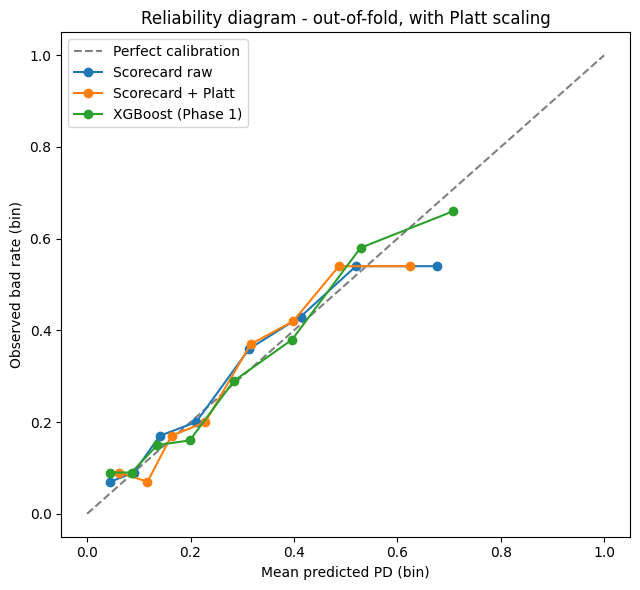

,model,brier_oof,brier_test,test_auc
0,Scorecard raw,0.1778,0.1655,0.7795
1,Scorecard + Platt,0.1776,0.1662,0.7795
2,XGBoost (Phase 1),0.1693,0.1611,0.7851


In [14]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

z_oof = logit(oof["WoE scorecard (LR)"]).reshape(-1, 1)

# Calibration slope / intercept on all OOF predictions (unregularised logistic fit)
platt = LogisticRegression(C=1e6, max_iter=1000).fit(z_oof, y_train)
platt_a, platt_b = float(platt.intercept_[0]), float(platt.coef_[0, 0])
print(f"Calibration intercept a = {platt_a:+.3f} | calibration slope b = {platt_b:.3f}")

# Nested OOF: calibrated PD for each row comes from a calibrator fitted on the other folds
oof_platt = cross_val_predict(LogisticRegression(C=1e6, max_iter=1000), z_oof, y_train,
                              cv=cv, method="predict_proba")[:, 1]

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], ls="--", c="gray", label="Perfect calibration")
for name, p in [("Scorecard raw", oof["WoE scorecard (LR)"]), ("Scorecard + Platt", oof_platt),
                ("XGBoost (Phase 1)", oof["XGBoost (Phase 1)"])]:
    frac_bad, mean_pred = calibration_curve(y_train, p, n_bins=N_BINS, strategy="quantile")
    ax.plot(mean_pred, frac_bad, marker="o", label=name)
ax.set_xlabel("Mean predicted PD (bin)"); ax.set_ylabel("Observed bad rate (bin)")
ax.set_title("Reliability diagram - out-of-fold, with Platt scaling")
ax.legend(); plt.tight_layout(); plt.show()

# Test set: calibrator fitted on all training OOF predictions, applied once to test PDs
test_pd_raw = test_pd["WoE scorecard (LR)"]
test_pd_platt = platt.predict_proba(logit(test_pd_raw).reshape(-1, 1))[:, 1]

platt_table = pd.DataFrame({
    "model": ["Scorecard raw", "Scorecard + Platt", "XGBoost (Phase 1)"],
    "brier_oof": [brier_score_loss(y_train, oof["WoE scorecard (LR)"]),
                  brier_score_loss(y_train, oof_platt),
                  brier_score_loss(y_train, oof["XGBoost (Phase 1)"])],
    "brier_test": [brier_score_loss(y_arr, test_pd_raw),
                   brier_score_loss(y_arr, test_pd_platt),
                   brier_score_loss(y_arr, test_pd["XGBoost (Phase 1)"])],
    "test_auc": [roc_auc_score(y_arr, test_pd_raw), roc_auc_score(y_arr, test_pd_platt),
                 roc_auc_score(y_arr, test_pd["XGBoost (Phase 1)"])],
}).round(4)
platt_table

## 9. Cut-off strategy (chosen on out-of-fold scores, confirmed on test)

Cut-offs are **selected on the 800 out-of-fold training predictions** (240 bad customers) and then
**applied unchanged to the test set**. Choosing them on the test set would make the reported test
numbers optimistic.

Each OOF PD is converted to a score with the same scaling, so OOF scores and test scores are on one scale.

Two views of the same decision (approve if score >= cut-off):
1. **Cost view**: cut-off that minimises expected cost with the 5:1 cost matrix. The theoretical optimum for a calibrated model is PD = 1/6.
2. **Business view**: strategy curve of approval rate vs bad rate among approved applicants; the risk team picks a point that matches its risk appetite.

Cost-optimal cut-off (OOF): 535.5  (PD 0.158)
Theoretical cut-off for PD 1/6: 533.6


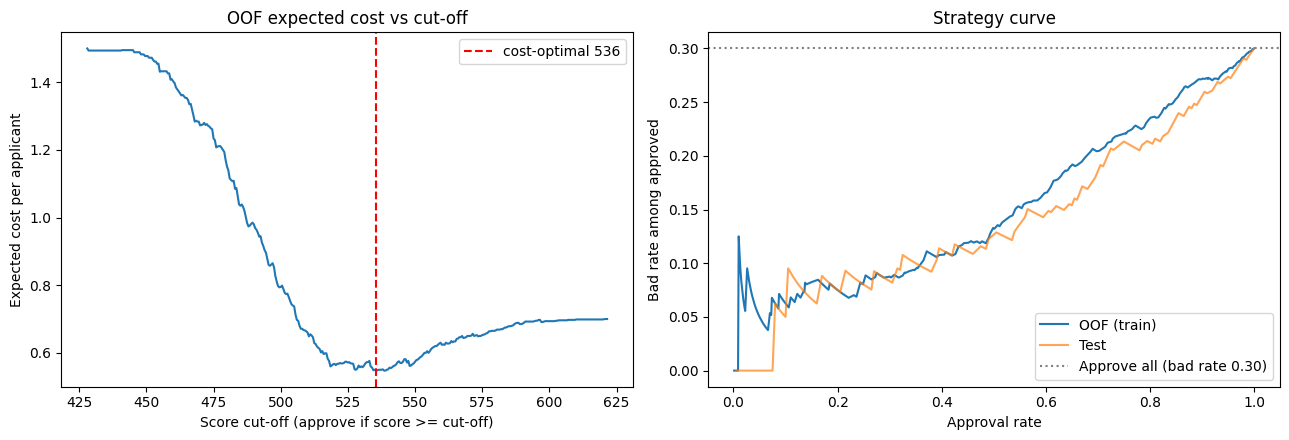

In [15]:
COST_FN, COST_FP = 5, 1

def strategy_table(y_true, score, cutoffs):
    # Approve if score >= cut-off; bad approved = FN (cost 5), good rejected = FP (cost 1)
    rows = []
    n_bad, n_good = (y_true == 1).sum(), (y_true == 0).sum()
    for c in cutoffs:
        approved = score >= c
        fn = (approved & (y_true == 1)).sum()
        fp = (~approved & (y_true == 0)).sum()
        rows.append({
            "cutoff": round(float(c), 1),
            "approval_rate": approved.mean(),
            "bad_rate_approved": y_true[approved].mean() if approved.any() else np.nan,
            "bad_caught": 1 - fn / n_bad,
            "good_rejected": fp / n_good,
            "cost_per_applicant": (COST_FN * fn + COST_FP * fp) / len(y_true),
        })
    return pd.DataFrame(rows)

y_tr = y_train.to_numpy()
oof_score = pd_to_score(np.clip(oof["WoE scorecard (LR)"], 1e-6, 1 - 1e-6))
test_score = scorecard.score(X_test)

# Cost-optimal cut-off on OOF scores
grid = np.arange(np.floor(oof_score.min()), np.ceil(oof_score.max()) + 1, 0.5)
oof_curve = strategy_table(y_tr, oof_score, grid)
cost_cutoff = float(oof_curve.loc[oof_curve["cost_per_applicant"].idxmin(), "cutoff"])
best_thr = float(score_to_pd(cost_cutoff))
print(f"Cost-optimal cut-off (OOF): {cost_cutoff:.1f}  (PD {best_thr:.3f})")
print(f"Theoretical cut-off for PD 1/6: {pd_to_score(1/6):.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(oof_curve["cutoff"], oof_curve["cost_per_applicant"])
axes[0].axvline(cost_cutoff, ls="--", c="red", label=f"cost-optimal {cost_cutoff:.0f}")
axes[0].set_xlabel("Score cut-off (approve if score >= cut-off)")
axes[0].set_ylabel("Expected cost per applicant")
axes[0].set_title("OOF expected cost vs cut-off"); axes[0].legend()

axes[1].plot(oof_curve["approval_rate"], oof_curve["bad_rate_approved"], label="OOF (train)")
test_curve = strategy_table(y_arr, test_score, grid)
axes[1].plot(test_curve["approval_rate"], test_curve["bad_rate_approved"], alpha=0.7, label="Test")
axes[1].axhline(y_tr.mean(), ls=":", c="gray", label=f"Approve all (bad rate {y_tr.mean():.2f})")
axes[1].set_xlabel("Approval rate"); axes[1].set_ylabel("Bad rate among approved")
axes[1].set_title("Strategy curve"); axes[1].legend()
plt.tight_layout(); plt.show()

In [16]:
# Cut-offs fixed on OOF scores for target approval rates, then applied to the test set
target_rates = [0.5, 0.6, 0.7, 0.8, 0.9]
cutoffs = [float(np.quantile(oof_score, 1 - r)) for r in target_rates] + [cost_cutoff]
rules = [f"approve ~{int(r * 100)}%" for r in target_rates] + ["cost-optimal (5:1)"]

strat_oof = strategy_table(y_tr, oof_score, cutoffs)
strat_test = strategy_table(y_arr, test_score, cutoffs)

strategy = pd.concat({"OOF (selection)": strat_oof.drop(columns="cutoff"),
                      "Test (confirmation)": strat_test.drop(columns="cutoff")}, axis=1)
strategy.insert(0, "cutoff", strat_oof["cutoff"])
strategy.insert(0, "rule", rules)
strategy.round(3)

rule cutoff OOF (selection)                               \
                               approval_rate bad_rate_approved bad_caught   
0        approve ~50%  516.3           0.500             0.132      0.779   
1        approve ~60%  506.2           0.600             0.167      0.667   
2        approve ~70%  495.9           0.700             0.205      0.521   
3        approve ~80%  486.1           0.800             0.234      0.375   
4        approve ~90%  474.0           0.900             0.272      0.183   
5  cost-optimal (5:1)  535.5           0.348             0.094      0.892   

                                   Test (confirmation)                    \
  good_rejected cost_per_applicant       approval_rate bad_rate_approved   
0         0.380              0.598               0.535             0.121   
1         0.286              0.700               0.595             0.143   
2         0.205              0.862               0.705             0.191   
3         0.125              1.025               0.810             0.216   
4         0.064              1.270               0.900             0.256   
5         0.550              0.548               0.340             0.103   

                                               
  bad_caught good_rejected cost_per_applicant  
0      0.783         0.329              0.555  
1      0.717         0.271              0.615  
2      0.550         0.186              0.805  
3      0.417         0.093              0.940  
4      0.233         0.043              1.180  
5      0.883         0.564              0.570

## 10. Points breakdown for one applicant (preview of reason codes)

For each variable: points received vs the maximum available. The largest gaps are the main
reasons for a low score. Phase 3 turns this into formal reason codes.

In [17]:
def points_breakdown(sc, row):
    # row: single-row DataFrame with the model features
    bp = sc.binning_process_
    table = sc.table(style="detailed")
    out = []
    for var in bp.get_support(names=True):
        ob = bp.get_binned_variable(var)
        bin_idx = int(ob.transform(row[var].to_numpy(), metric="indices")[0])
        var_tab = table[table["Variable"] == var].reset_index(drop=True)
        pts = float(var_tab.loc[bin_idx, "Points"])
        out.append({"variable": var, "value": row[var].iloc[0], "bin": var_tab.loc[bin_idx, "Bin"],
                    "points": pts, "max_points": float(var_tab["Points"].max())})
    res = pd.DataFrame(out)
    res["points_lost"] = res["max_points"] - res["points"]
    return res.sort_values("points_lost", ascending=False).reset_index(drop=True)

example = X_test.iloc[[0]]
bd = points_breakdown(scorecard, example)
print("Score from breakdown:", round(bd["points"].sum(), 2),
      "| scorecard.score():", round(float(scorecard.score(example)[0]), 2))
bd.round(1)

Score from breakdown: 530.45 | scorecard.score(): 530.45


,variable,value,bin,points,max_points,points_lost
0,Duration,18,"[15.50, 34.50)",68.8,112.2,43.4
1,Checking account,moderate,[moderate],63.1,100.9,37.8
2,Purpose,business,"[business, vacation/others]",69.8,83.9,14.0
3,Credit amount,1913,"[718.00, 3913.50)",75.3,75.6,0.4
4,Age,36,"[34.50, inf)",78.4,78.4,0.0
5,Saving accounts,rich,[rich],98.7,98.7,0.0
6,Housing,own,[own],76.3,76.3,0.0


## 11. Save the scorecard for the app

In [18]:
artifact = {
    "scorecard": scorecard,
    "features": features,
    "num_features": num_features,
    "cat_features": cat_features,
    "scaling": {"pdo": PDO, "base_score": BASE_SCORE, "base_odds": BASE_ODDS,
                "factor": factor, "offset": offset},
    "cost_cutoff": cost_cutoff,
    "cost_pd_threshold": best_thr,
    "strategy_cutoffs": dict(zip(rules, [round(c, 1) for c in cutoffs])),
    "platt": {"a": platt_a, "b": platt_b},
    "positive_class": "bad",
}
joblib.dump(artifact, "credit_scorecard.pkl")
print("Saved credit_scorecard.pkl")
print("Pin these in requirements.txt:",
      f"optbinning=={optbinning.__version__}", f"scikit-learn=={sklearn.__version__}")

Saved credit_scorecard.pkl
Pin these in requirements.txt: optbinning==1.0.0 scikit-learn==1.6.1


## 12. Notes and limitations

- The test set has about 60 bad customers; strategy-table rates move by several percentage points with a handful of applicants.
- Strategy and calibration results describe a 1970s-80s German sample and are a method demonstration, not a lending policy.
- Binning is fitted on 800 rows; some bins are close to the 5% minimum and their WoE is noisy.
- The 5:1 cost matrix ignores revenue from good customers, which is why the cost-optimal cut-off rejects many applicants.